In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import RegularPolygon
from matplotlib.collections import PatchCollection
import stim

import os 

while 'honeycomb.py' not in os.listdir():
    os.chdir("..")

from honeycomb import CSSHoneycomb
from operations import Detector

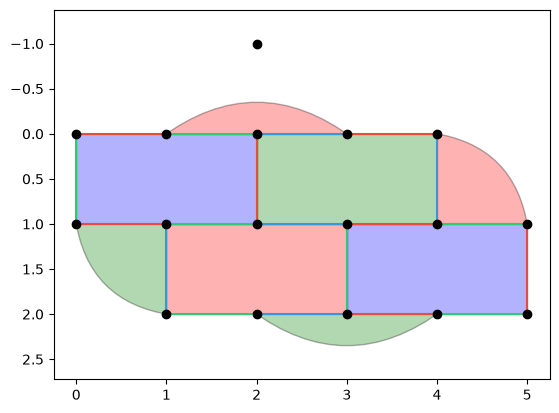

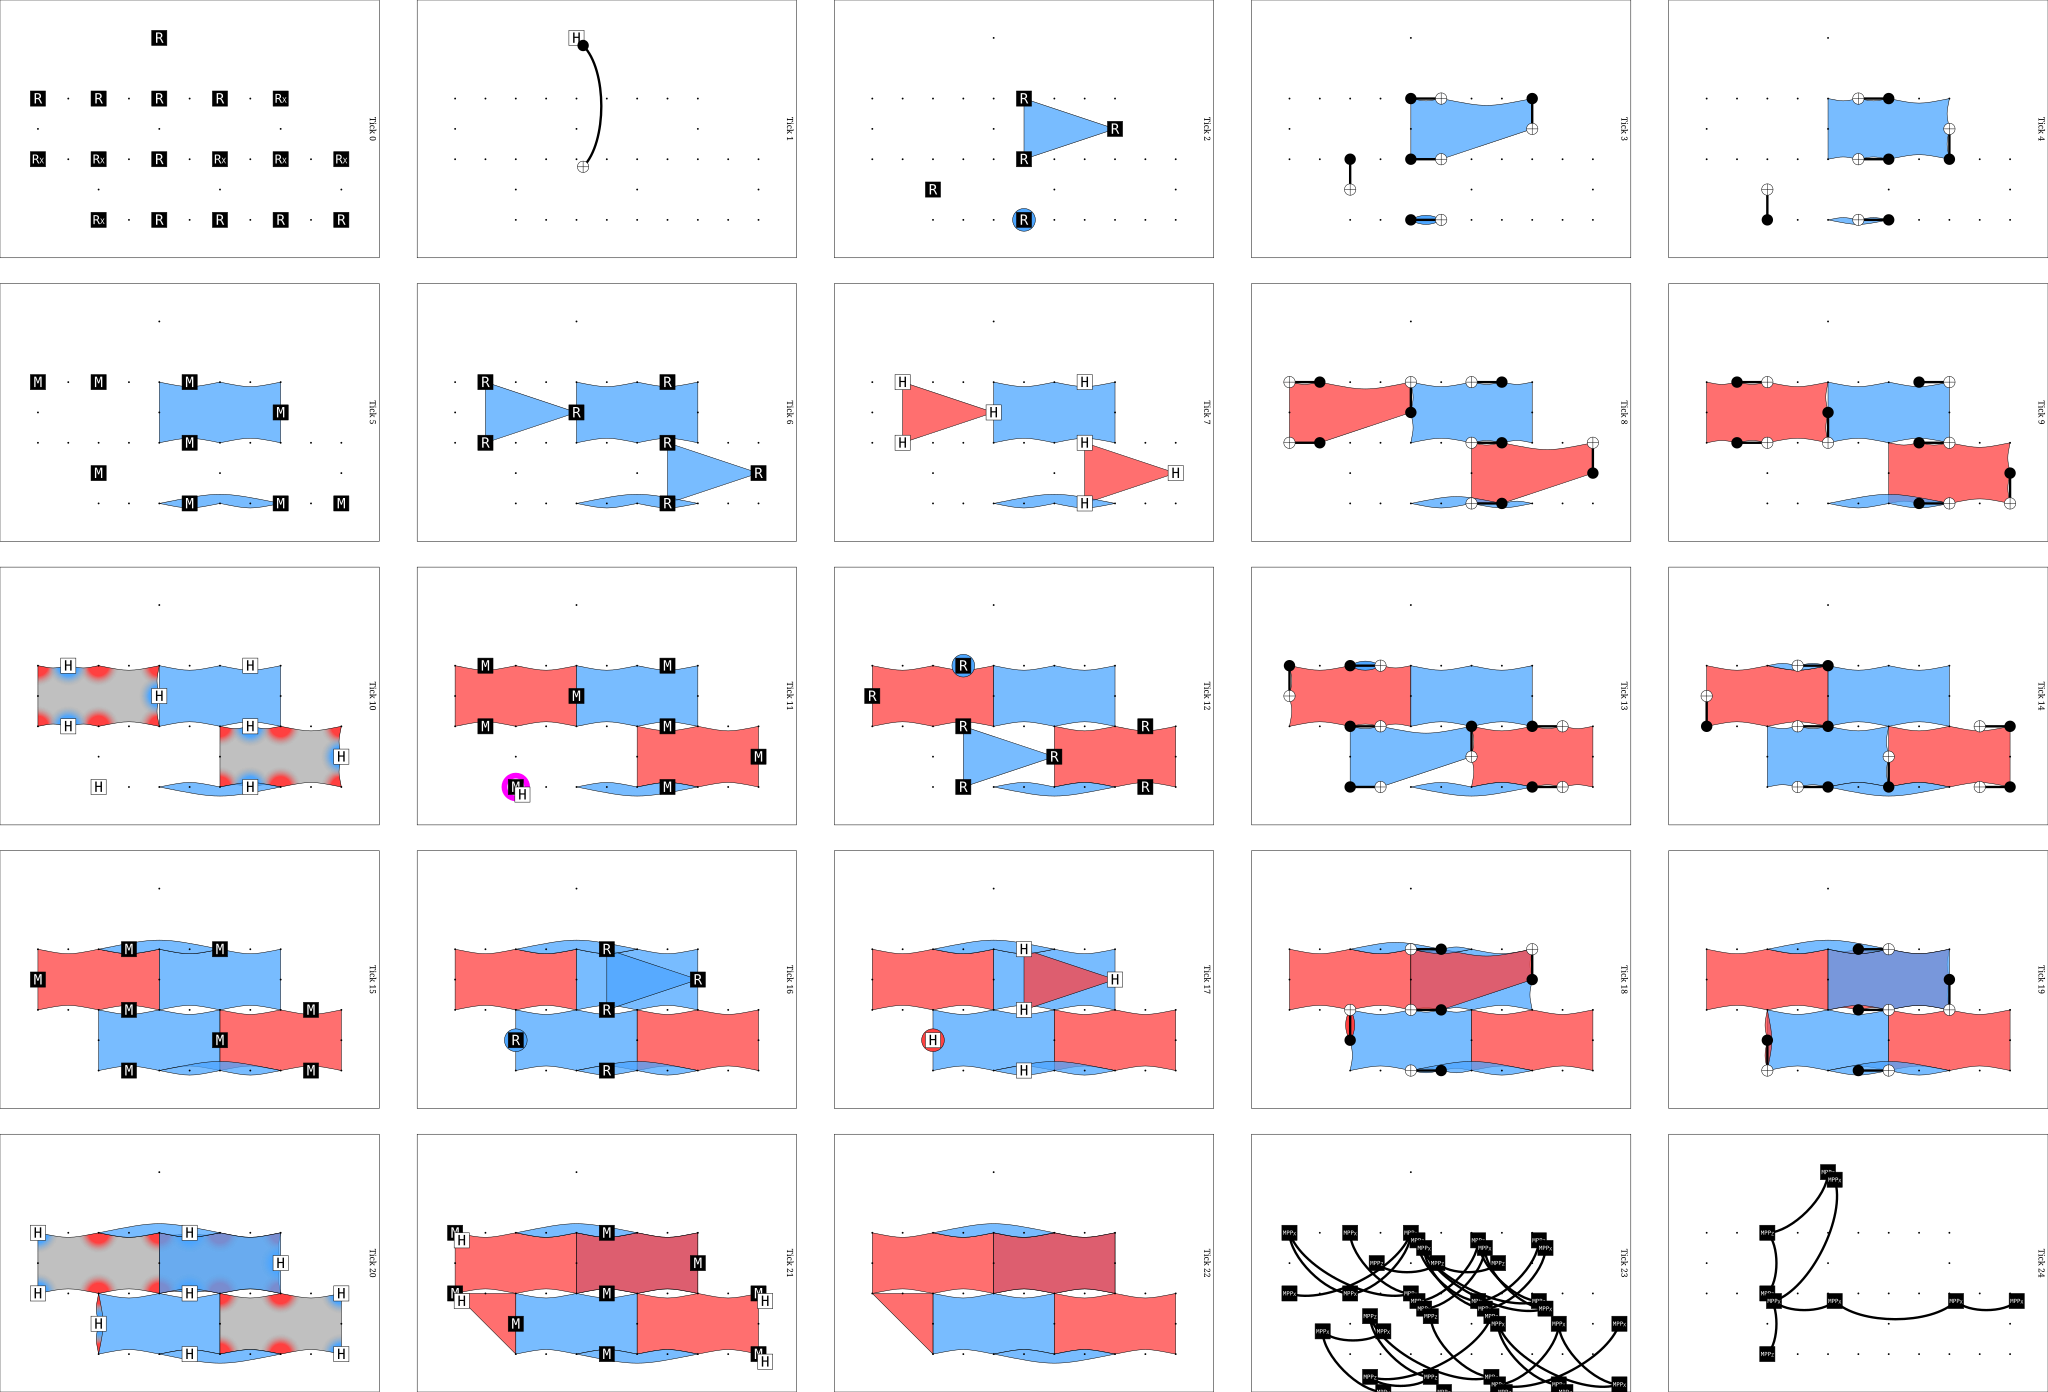

In [2]:
COLOUR_MAP = {
    'r' : 'red',
    'g' : 'green',
    'b' : 'blue'
}

def measurement_cycle(honey: CSSHoneycomb, cycle=["rZ", "gX", "bZ", "rX", "gZ", "bX"]):
    """
    measure our stabilizers
    """

    string = ""
    for m in cycle:
        
        if m == "gZ":
            print("" ,end="")
        
        colour = COLOUR_MAP[m[0]]
        flavour = m[1]

        string += f"#{colour}{flavour}\n"
        string += honey.get_measurement(colour, flavour) + "\n"
        string += honey.tick()
        
        # detectors = honey.get_detectors()
        # string += honey.write_detectors(detectors, honey.clock)
        
        # print(detectors)
    
    return string

s = CSSHoneycomb(ncols=5, nrows=3, config_filepath="config/5x3.json")
s.plot_surface()
string = s.initialise_circuit()
string += s.prepare_qubits()
string += measurement_cycle(s, cycle=["bZ", "rX", "gZ", "bX"])
string += s.final_readout()
string += s.tick()
string += s.write_logicals("blue", "X")

circuit = stim.Circuit(string)
circuit.diagram("detslice-with-ops-svg")

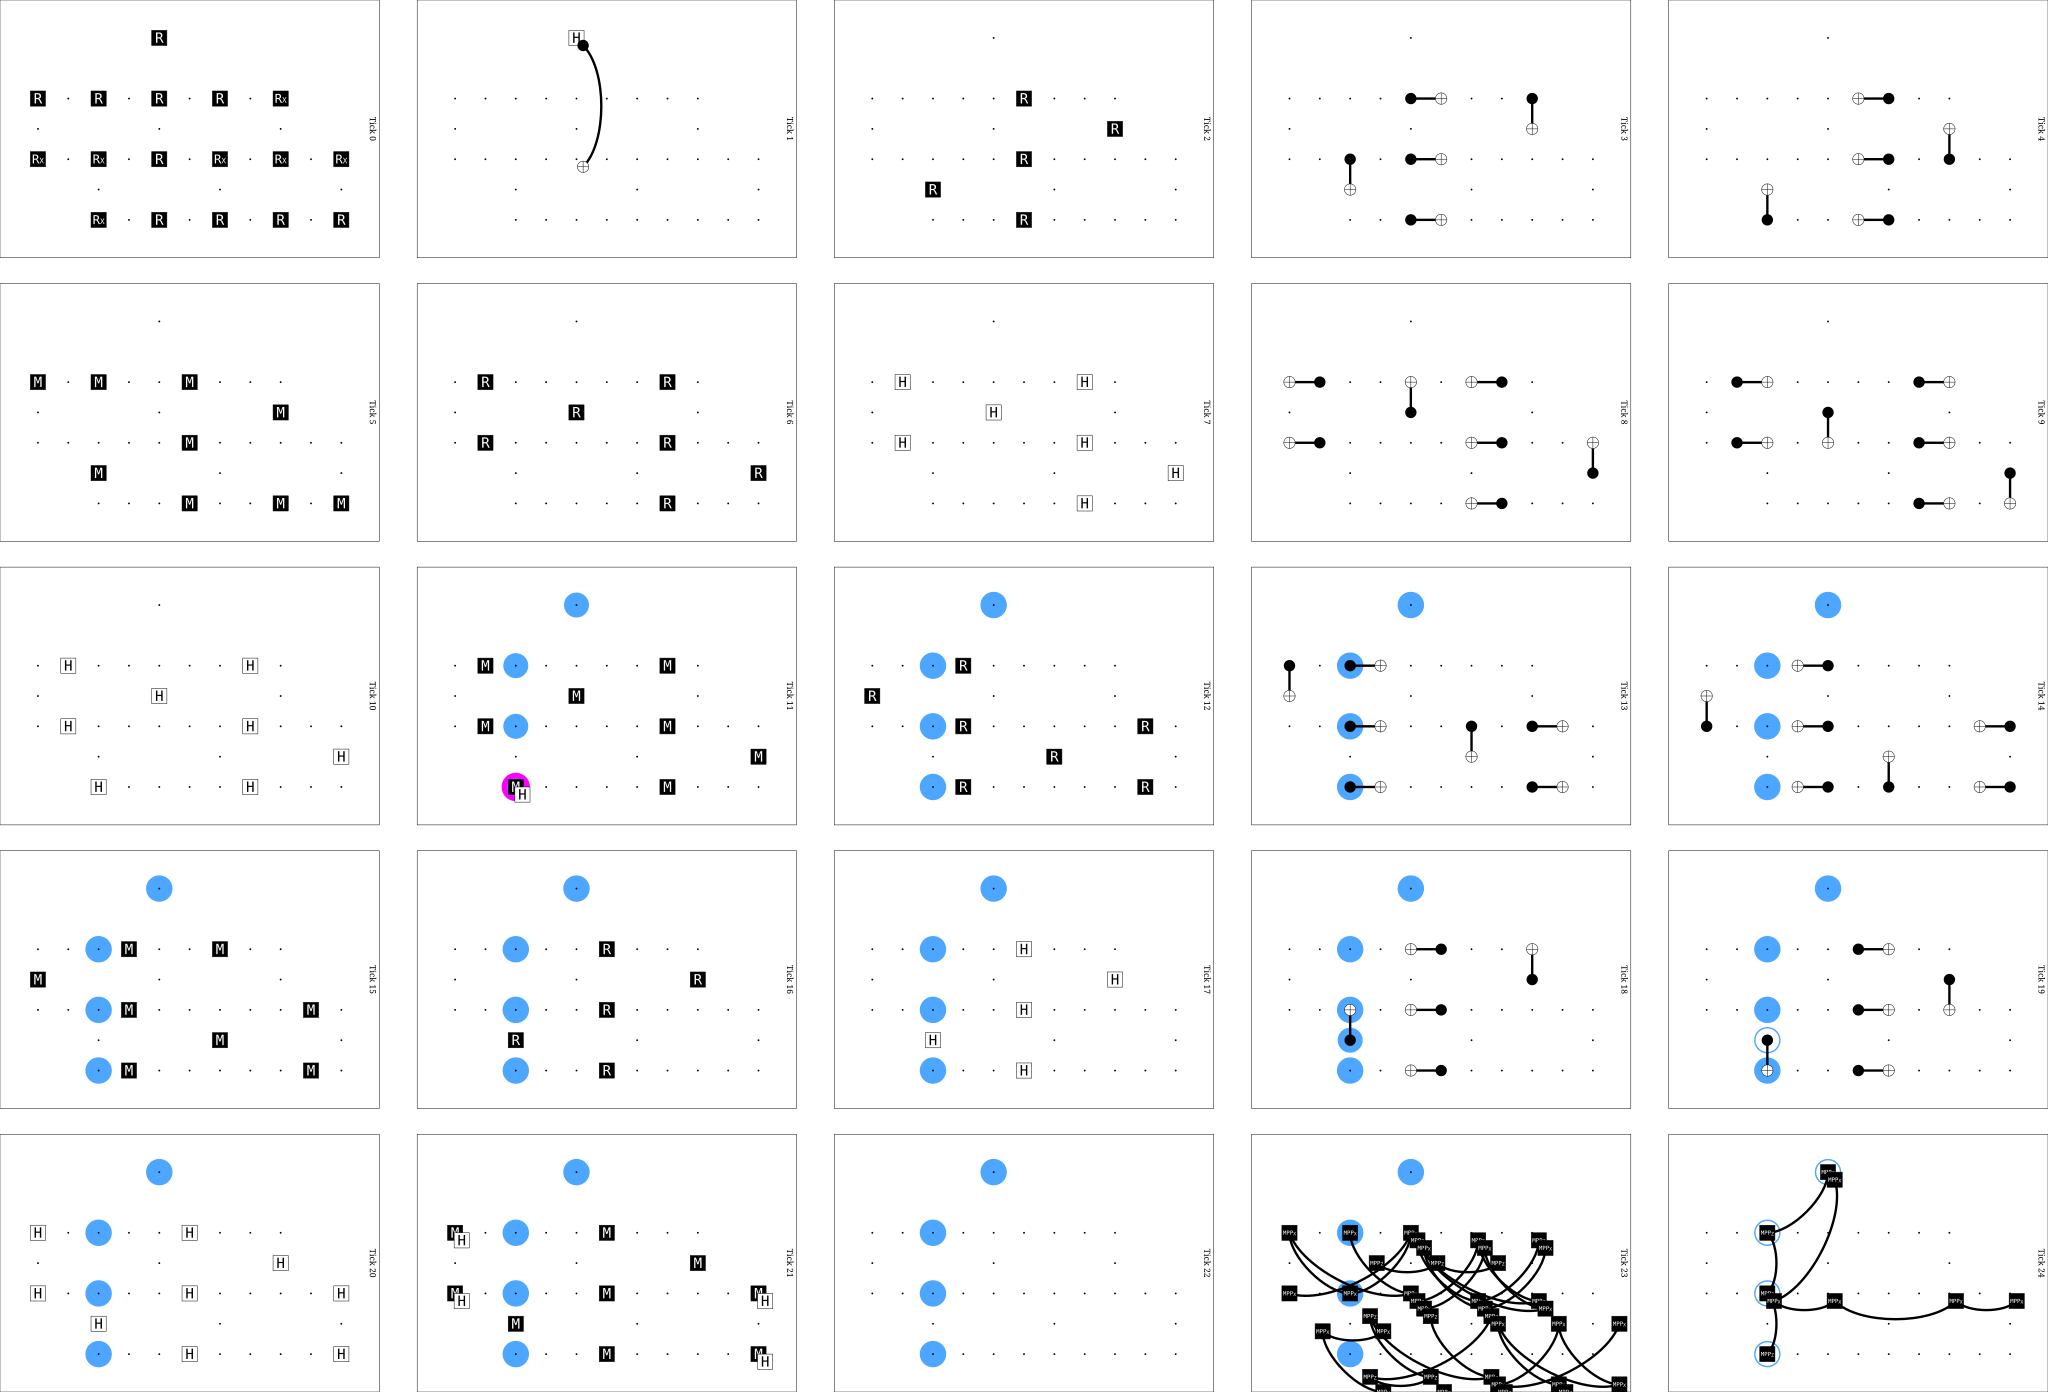

In [3]:
circuit.diagram('detslice-with-ops-svg', filter_coords=['L0','L1'])


In [4]:
# Graphlike distance (fast, needs errors that decompose into edges)
err = circuit.shortest_graphlike_error(ignore_ground_truth=False) if False else circuit.shortest_graphlike_error()
print("distance:", len(err))

# Fallback if the DEM has hyperedges that don't decompose
err = circuit.search_for_undetectable_logical_errors(
    dont_explore_detection_event_sets_with_size_above=4,
    dont_explore_edges_with_degree_above=4,
    dont_explore_edges_increasing_symptom_degree=True,
)
print("distance:", len(err))

ValueError: The circuit contains non-deterministic observables.

To make an SVG picture of the problem, you can use the python API like this:
    your_circuit.diagram('detslice-with-ops-svg', tick=range(6, 16), filter_coords=['L0', ])
or the command line API like this:
    stim diagram --in your_circuit_file.stim --type detslice-with-ops-svg --tick 6:16 --filter_coords L0 > output_image.svg

This was discovered while analyzing a Z-basis measurement (M) on:
    qubit 12 [coords (1, 2)]

The collapse anti-commuted with these detectors/observables:
    L0

The backward-propagating error sensitivity for L0 was:
    Z0 [coords (2, -1)]
    Z2 [coords (1, 0)]
    Z7 [coords (1, 1)]
    X12 [coords (1, 2)]

Circuit stack trace:
    during TICK layer #12 of 25
    at instruction #61 [which is M 18 20 22 24 29 31 34 12]